# 02 - Naive Bayes & SVM

Train, evaluate và tuning Naive Bayes (GaussianNB) và SVM trên train/test split dùng chung.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

from src.preprocessing import prepare_data
from src.naive_bayes import train_naive_bayes, tune_naive_bayes
from src.svm_model import TRAIN_SAMPLE_SIZE, TUNE_SAMPLE_SIZE, train_svm, tune_svm
from src.evaluation import evaluate_model, plot_confusion_matrix, print_report, save_metrics

X_train, X_test, y_train, y_test = prepare_data()
print(X_train.shape, X_test.shape)

(69300, 32) (17325, 32)


## 1. Naive Bayes baseline

In [2]:
nb_base = train_naive_bayes(X_train, y_train)
nb_base_metrics = evaluate_model(nb_base, X_test, y_test, "Naive Bayes", "baseline")
print_report(nb_base, X_test, y_test)
nb_base_metrics

              precision    recall  f1-score   support

Not canceled     0.8897    0.4204    0.5709     12530
    Canceled     0.3632    0.8638    0.5114      4795

    accuracy                         0.5431     17325
   macro avg     0.6264    0.6421    0.5412     17325
weighted avg     0.7440    0.5431    0.5545     17325



{'model': 'Naive Bayes',
 'stage': 'baseline',
 'accuracy': 0.5430880230880231,
 'precision': 0.3631740464708461,
 'recall': 0.8638164754953076,
 'f1': 0.511358024691358,
 'roc_auc': 0.7445389709119385}

## 2. Naive Bayes tuning (`var_smoothing`)

GridSearchCV 5-fold trên tập train, tối ưu F1.

In [3]:
nb_tuned, nb_params, nb_cv = tune_naive_bayes(X_train, y_train)
print("Best params:", nb_params, "CV F1:", round(nb_cv, 4))
nb_tuned_metrics = evaluate_model(nb_tuned, X_test, y_test, "Naive Bayes", "tuned")
print_report(nb_tuned, X_test, y_test)
nb_tuned_metrics

Best params: {'model__var_smoothing': np.float64(0.01)} CV F1: 0.5539
              precision    recall  f1-score   support

Not canceled     0.8959    0.5538    0.6845     12530
    Canceled     0.4164    0.8319    0.5550      4795

    accuracy                         0.6308     17325
   macro avg     0.6562    0.6928    0.6197     17325
weighted avg     0.7632    0.6308    0.6486     17325



{'model': 'Naive Bayes',
 'stage': 'tuned',
 'accuracy': 0.6307647907647908,
 'precision': 0.4163883089770355,
 'recall': 0.8319082377476538,
 'f1': 0.5549913043478261,
 'roc_auc': 0.763490043083253}

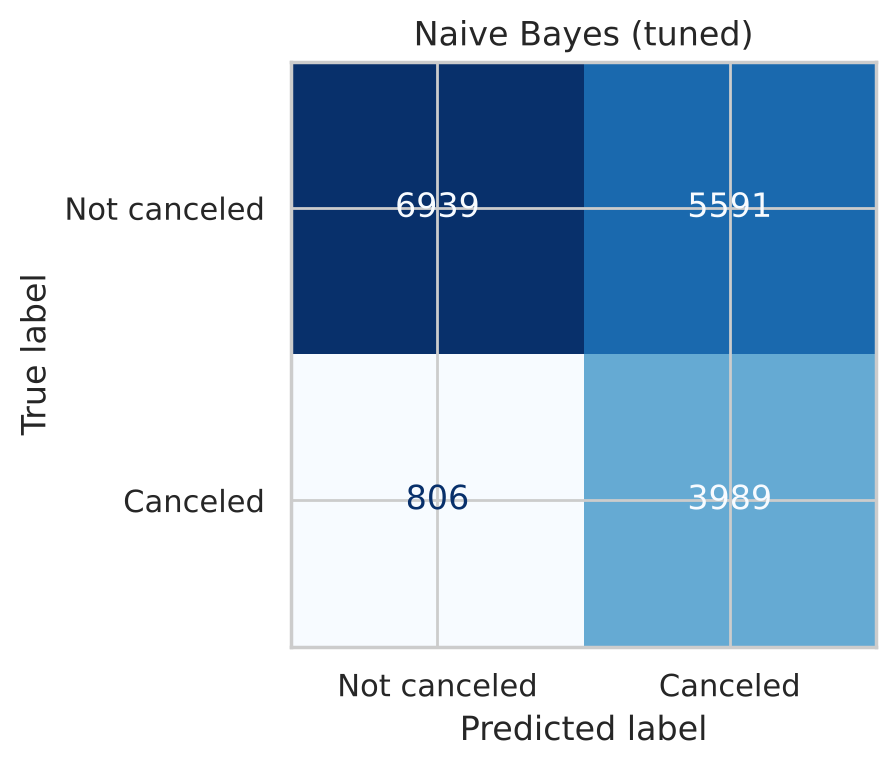

In [4]:
plot_confusion_matrix(nb_tuned, X_test, y_test, "Naive Bayes (tuned)", "confusion_matrix_nb.png")
plt.show()

## 3. SVM baseline

SVC có độ phức tạp ~O(n²), nên SVM được train trên mẫu phân tầng gồm `TRAIN_SAMPLE_SIZE` booking lấy từ tập train. Dữ liệu được scale bằng `StandardScaler`. Đánh giá vẫn trên **toàn bộ** test set chung.

In [5]:
svm_base = train_svm(X_train, y_train)
svm_base_metrics = evaluate_model(svm_base, X_test, y_test, "SVM", "baseline")
print("Train sample size:", TRAIN_SAMPLE_SIZE)
print_report(svm_base, X_test, y_test)
svm_base_metrics

Train sample size: 20000


              precision    recall  f1-score   support

Not canceled     0.8243    0.9366    0.8769     12530
    Canceled     0.7429    0.4784    0.5820      4795

    accuracy                         0.8098     17325
   macro avg     0.7836    0.7075    0.7295     17325
weighted avg     0.8018    0.8098    0.7953     17325



{'model': 'SVM',
 'stage': 'baseline',
 'accuracy': 0.8098124098124098,
 'precision': 0.7428756476683938,
 'recall': 0.478415015641293,
 'f1': 0.5820119243942662,
 'roc_auc': 0.8559244507655037}

## 4. SVM tuning (`C`, `kernel`, `gamma`)

GridSearchCV 3-fold trên mẫu nhỏ hơn để tiết kiệm thời gian, sau đó train lại cấu hình tốt nhất trên mẫu train lớn.

In [6]:
svm_tuned, svm_params, svm_cv = tune_svm(X_train, y_train)
print("Tune sample size:", TUNE_SAMPLE_SIZE)
print("Best params:", svm_params, "CV F1:", round(svm_cv, 4))
svm_tuned_metrics = evaluate_model(svm_tuned, X_test, y_test, "SVM", "tuned")
print_report(svm_tuned, X_test, y_test)
svm_tuned_metrics

Tune sample size: 6000
Best params: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'} CV F1: 0.5733


              precision    recall  f1-score   support

Not canceled     0.8423    0.9133    0.8764     12530
    Canceled     0.7095    0.5533    0.6217      4795

    accuracy                         0.8137     17325
   macro avg     0.7759    0.7333    0.7491     17325
weighted avg     0.8056    0.8137    0.8059     17325



{'model': 'SVM',
 'stage': 'tuned',
 'accuracy': 0.8136796536796537,
 'precision': 0.7095480074886333,
 'recall': 0.5532846715328467,
 'f1': 0.6217483009139911,
 'roc_auc': 0.8586707439163733}

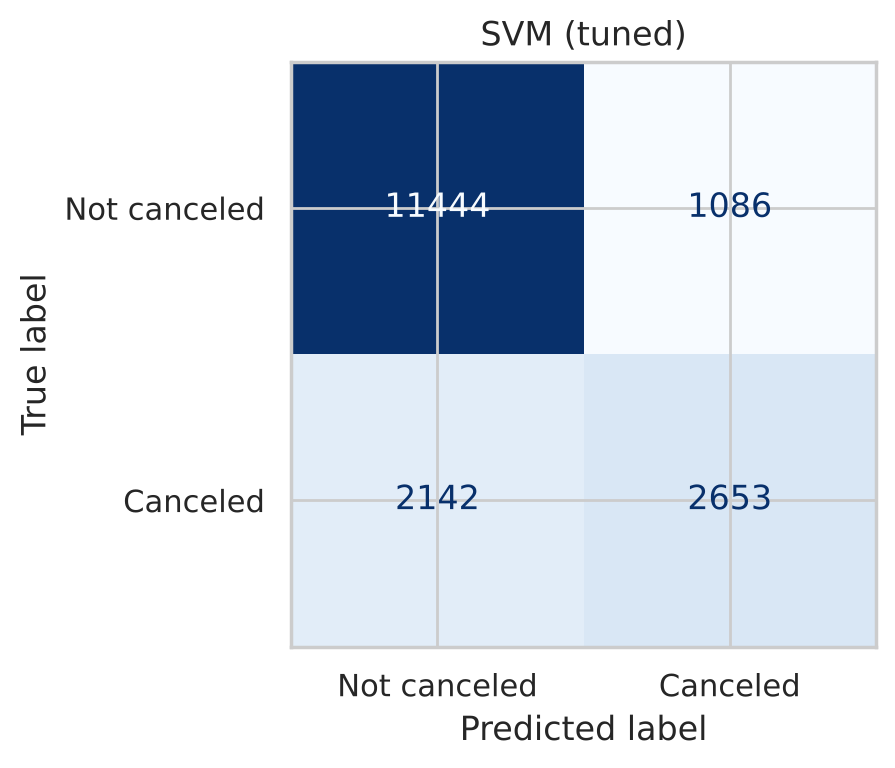

In [7]:
plot_confusion_matrix(svm_tuned, X_test, y_test, "SVM (tuned)", "confusion_matrix_svm.png")
plt.show()

## 5. Lưu kết quả

In [8]:
table = save_metrics([nb_base_metrics, nb_tuned_metrics, svm_base_metrics, svm_tuned_metrics])
joblib.dump(nb_tuned, MODELS_DIR / "nb_tuned.joblib")
joblib.dump(svm_tuned, MODELS_DIR / "svm_tuned.joblib")
table

,model,stage,accuracy,precision,recall,f1,roc_auc
0,Naive Bayes,baseline,0.5431,0.3632,0.8638,0.5114,0.7445
1,Naive Bayes,tuned,0.6308,0.4164,0.8319,0.5550,0.7635
2,SVM,baseline,0.8098,0.7429,0.4784,0.5820,0.8559
3,SVM,tuned,0.8137,0.7095,0.5533,0.6217,0.8587


**Nhận xét:** Naive Bayes giả định các đặc trưng độc lập và phân phối chuẩn, không phù hợp với dữ liệu one-hot → recall cao nhưng precision thấp. SVM RBF tách lớp tốt hơn rõ rệt (ROC-AUC ~0.86); tuning tăng `C` giúp cải thiện recall và F1.